# 2. Global convergence and entrance times

Clean version of the current experiment. Run cells from top to bottom. Original notebooks are unchanged.

The factor $q_0=1-\delta/((d-1)\Delta)$ is a limiting local reference, not a proved finite-region or global error bound.


This experiment starts uniformly on the sphere and separates the time to enter
$\mathcal E_{\eta,\delta}$ from contraction after entrance. Let
$$T_\eta=\inf\{k\ge0:\varepsilon_k\le\eta\delta\}.$$
For $d\ge3$, the theorem gives
$$P(T_\eta>k)\le(1-p_\eta)^k,$$
where $p_\eta=P(Z\ge1-\eta\delta/\Delta)$ and
$Z\sim\mathrm{Beta}(1/2,(d-2)/2)$, and
$$\mathbb E[\varepsilon_k]\le\min_{0\le j\le k}
\{\Delta(1-p_\eta)^j+\eta\delta q_\eta^{k-j}\}.$$

Run all cells in order with `operator_norm.py` in the same folder.
The cap bound can be almost uninformative over a practical simulation horizon;
that is a feature to report rather than hide.

Black curves now use the limiting local reference
$q_0=1-\delta/((d-1)\Delta)$. The global panel shows one reference
$\bar\varepsilon_0q_0^k$ per matrix. The post-entry panel shows
$\eta\delta q_0^n$ for the different entrance thresholds.
These are comparison references, not guaranteed finite-region or global bounds.
The purple optimized global bound retains the theorem's valid eta-dependent q;
the entrance-time bounds and empirical runs are unchanged. The black and gray
curves should no longer be added to obtain the theorem's global bound.


In [3]:
from pathlib import Path
import sys
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt

from operator_norm import (
    estimate_operator_norm, controlled_spectrum, local_initial_vectors,
    diagonal_ensemble, rate_constants, global_bound,
    bootstrap_mean_band, fitted_mean_rate,
)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'font.size': 10, 'savefig.bbox': 'tight'})
# LaTeX-style text without requiring a local TeX installation. Set this to
# True only if a working LaTeX distribution is installed on your machine.
USE_SYSTEM_LATEX = False
HERE = Path.cwd()
import matplotlib as mpl
mpl.rcParams.update({
    'text.usetex': USE_SYSTEM_LATEX,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'axes.unicode_minus': False,
    'figure.dpi': 120,
    'savefig.dpi': 200,
})
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__,
      '| SciPy:', scipy.__version__, '| Matplotlib:', matplotlib.__version__)


Python: 3.14.7 | NumPy: 2.5.2 | SciPy: 1.18.1 | Matplotlib: 3.11.1


In [ ]:
PROFILE = 'quick'  # 'quick' or 'full'
ETAS = [0.01, 0.1, 0.5]
ETA_LINESTYLES = ['-', '--', ':']  # solid, dashed, dotted, respectively
assert len(ETAS) == len(ETA_LINESTYLES) and len(set(ETAS)) == len(ETAS)
assert all(0 < eta < 1 for eta in ETAS)
ETA_STYLES = dict(zip(ETAS, ETA_LINESTYLES))
ETA_TAG = 'etas_' + '_'.join(f'{eta:g}' for eta in ETAS)
from matplotlib.lines import Line2D

def comparison_legend(ax, categories, *, theory=False, exact=False, loc='best', entry_band=False):
    handles = [Line2D([], [], color=color, label=label) for label, color in categories]
    handles += [Line2D([], [], color='black', linestyle=ETA_STYLES[eta],
                       label=rf'$\eta={eta:g}$') for eta in ETAS]
    if theory:
        handles += [Line2D([], [], color='black', marker='x', linewidth=1,
                           label=r'Limiting local reference $q_0^k$ (×)'),
                    Line2D([], [], color='gray', marker='+', linewidth=1,
                           label=r'Entrance survival $(1-p_\eta)^k$ (+)')]
    if exact:
        handles.append(Line2D([], [], color='black', linestyle='-.', label='Exact expectation'))
    if entry_band:
        from matplotlib.patches import Patch
        handles.append(Patch(facecolor='C3',alpha=.14,
                             label=r'95% upper-limit crossing range across $\eta$'))
    ax.legend(handles=handles, fontsize=8, loc=loc)
SEED = 20260918
SETTINGS = {
    'quick': dict(cases=[(20,.5),(20,.1),(60,.1)], runs=128, steps=3500, post_steps=1200, bootstrap=150),
    'full': dict(cases=[(20,.5),(20,.1),(100,.1),(500,.03)], runs=500, steps=100000, post_steps=20000, bootstrap=500),
}
cfg = SETTINGS[PROFILE]
OUT = HERE / 'results' / '02_global' / PROFILE / ETA_TAG
OUT.mkdir(parents=True, exist_ok=True)
print(cfg)
experiments = []
for ETA in ETAS:
    for case, (d, gap) in enumerate(cfg['cases']):
        lam = controlled_spectrum(d, gap)
        constants = rate_constants(lam, ETA)
        data = diagonal_ensemble(lam, runs=cfg['runs'], steps=cfg['steps'], seed=SEED+case, eta=ETA)
        censored = np.count_nonzero(data['hit_times'] < 0)
        print(f'eta={ETA:g}, d={d}, gap={gap:g}: censored={censored}/{cfg["runs"]}; log10(p)={constants["logp"]/np.log(10):.2f}')
        if constants['p'] == 0:
            print('  p underflowed: the plotted survival bound uses its conservative limit 1.')
        entered = data['hit_times'][data['hit_times'] >= 0]
        print('  median T among observed entrants:', np.median(entered) if len(entered) else 'none')
        post = None
        # Restart ALL trajectories from their first-entry states with fresh independent
        # randomness. This has the correct post-stopping-time law. No selected subset.
        if censored == 0:
            post = diagonal_ensemble(lam, runs=cfg['runs'], steps=cfg['post_steps'],
                                     seed=SEED+1000+case, initial=data['hit_vectors'], eta=ETA)['errors']
        else:
            print('  Post-entry panel skipped: increase the global budget; do not drop censored runs.')
        experiments.append(dict(d=d, gap=gap, eta=ETA, constants=constants, data=data, post=post))
        payload = dict(errors=data['errors'], hit_times=data['hit_times'],
                       hit_vectors=data['hit_vectors'], lambdas=lam, eta=ETA,
                       global_seed=SEED+case, post_seed=SEED+1000+case)
        if post is not None:
            payload['post_errors'] = post
        np.savez_compressed(OUT / f'd{d}_g{gap:g}_eta_{ETA:g}.npz', **payload)

{'cases': [(20, 0.5), (20, 0.1), (60, 0.1)], 'runs': 128, 'steps': 3500, 'post_steps': 1200, 'bootstrap': 150}
eta=0.01, d=20, gap=0.5: censored=0/128; log10(p)=-21.44
  median T among observed entrants: 95.0
eta=0.01, d=20, gap=0.1: censored=0/128; log10(p)=-27.73
  median T among observed entrants: 255.5
eta=0.01, d=60, gap=0.1: censored=0/128; log10(p)=-87.98
  median T among observed entrants: 826.0


## Global means and entrance-time survival

The expectation bound is optimized over integer $j$. Convexity of its continuous
extension allows evaluation at just the adjacent integers to the clipped minimizer.
The error panel uses arithmetic means with pointwise trajectory-bootstrap bands.

Unentered trajectories are right-censored at the common simulation horizon and
are included in every survival estimate. Zero empirical survival is not plotted
on the logarithmic axis. With $N$ observed trajectories and no survivors, a
pointwise one-sided 95% binomial upper bound is $1-0.05^{1/N}$, not zero.

Across all comparison plots, line style identifies $\eta$: solid for 0.01,
dashed for 0.1, and dotted for 0.5. Colors identify the other experiment settings.
Black limiting local references (×) and gray entrance-survival references (+) use the same $\eta$ styles; exact reference
curves use dash-dot. Shaded intervals are pointwise 95% trajectory-bootstrap
confidence intervals unless explicitly labeled as standard deviation.
Seeds are reused across $\eta$ for a coupled comparison; different $\eta$
curves are not independent experiment groups. Output names include $\eta$.

In this global experiment, $\eta$ changes the entrance threshold, not the
uniform starting vectors or updates. Reusing each case's seed therefore gives
identical global error curves across $\eta$; the global mean is drawn once.
Entrance times, post-entry continuations, and bounds depend on $\eta$.


The red vertical band in each first-column panel spans the earliest to latest
crossing of the existing horizontal 95% upper-limit reference across eta.
The reference level is $u_N=1-0.05^{1/N}$, and each crossing is the first integer
$k$ with empirical survival $\widehat S_\eta(k)\leq u_N$. Red points in the
second column identify these crossings. The separate 5% survival guide is removed.

The level $u_N$ is the one-sided 95% binomial upper bound when zero survivors
are observed. At nonzero counts it serves here only as a fixed reference level;
crossing it is not itself a confidence statement about the surviving fraction.
The red band is a range across eta, not a confidence interval. Censored
crossings are explicitly labeled. Exact crossing times and levels are exported.

The eta=0 reference is the limit of the local factor as eta tends to zero; it is not asserted to be optimal or to bound finite-error starts. The optimized global bounds still use q_eta because replacing q_eta by q0 there would not be justified by the theorem.


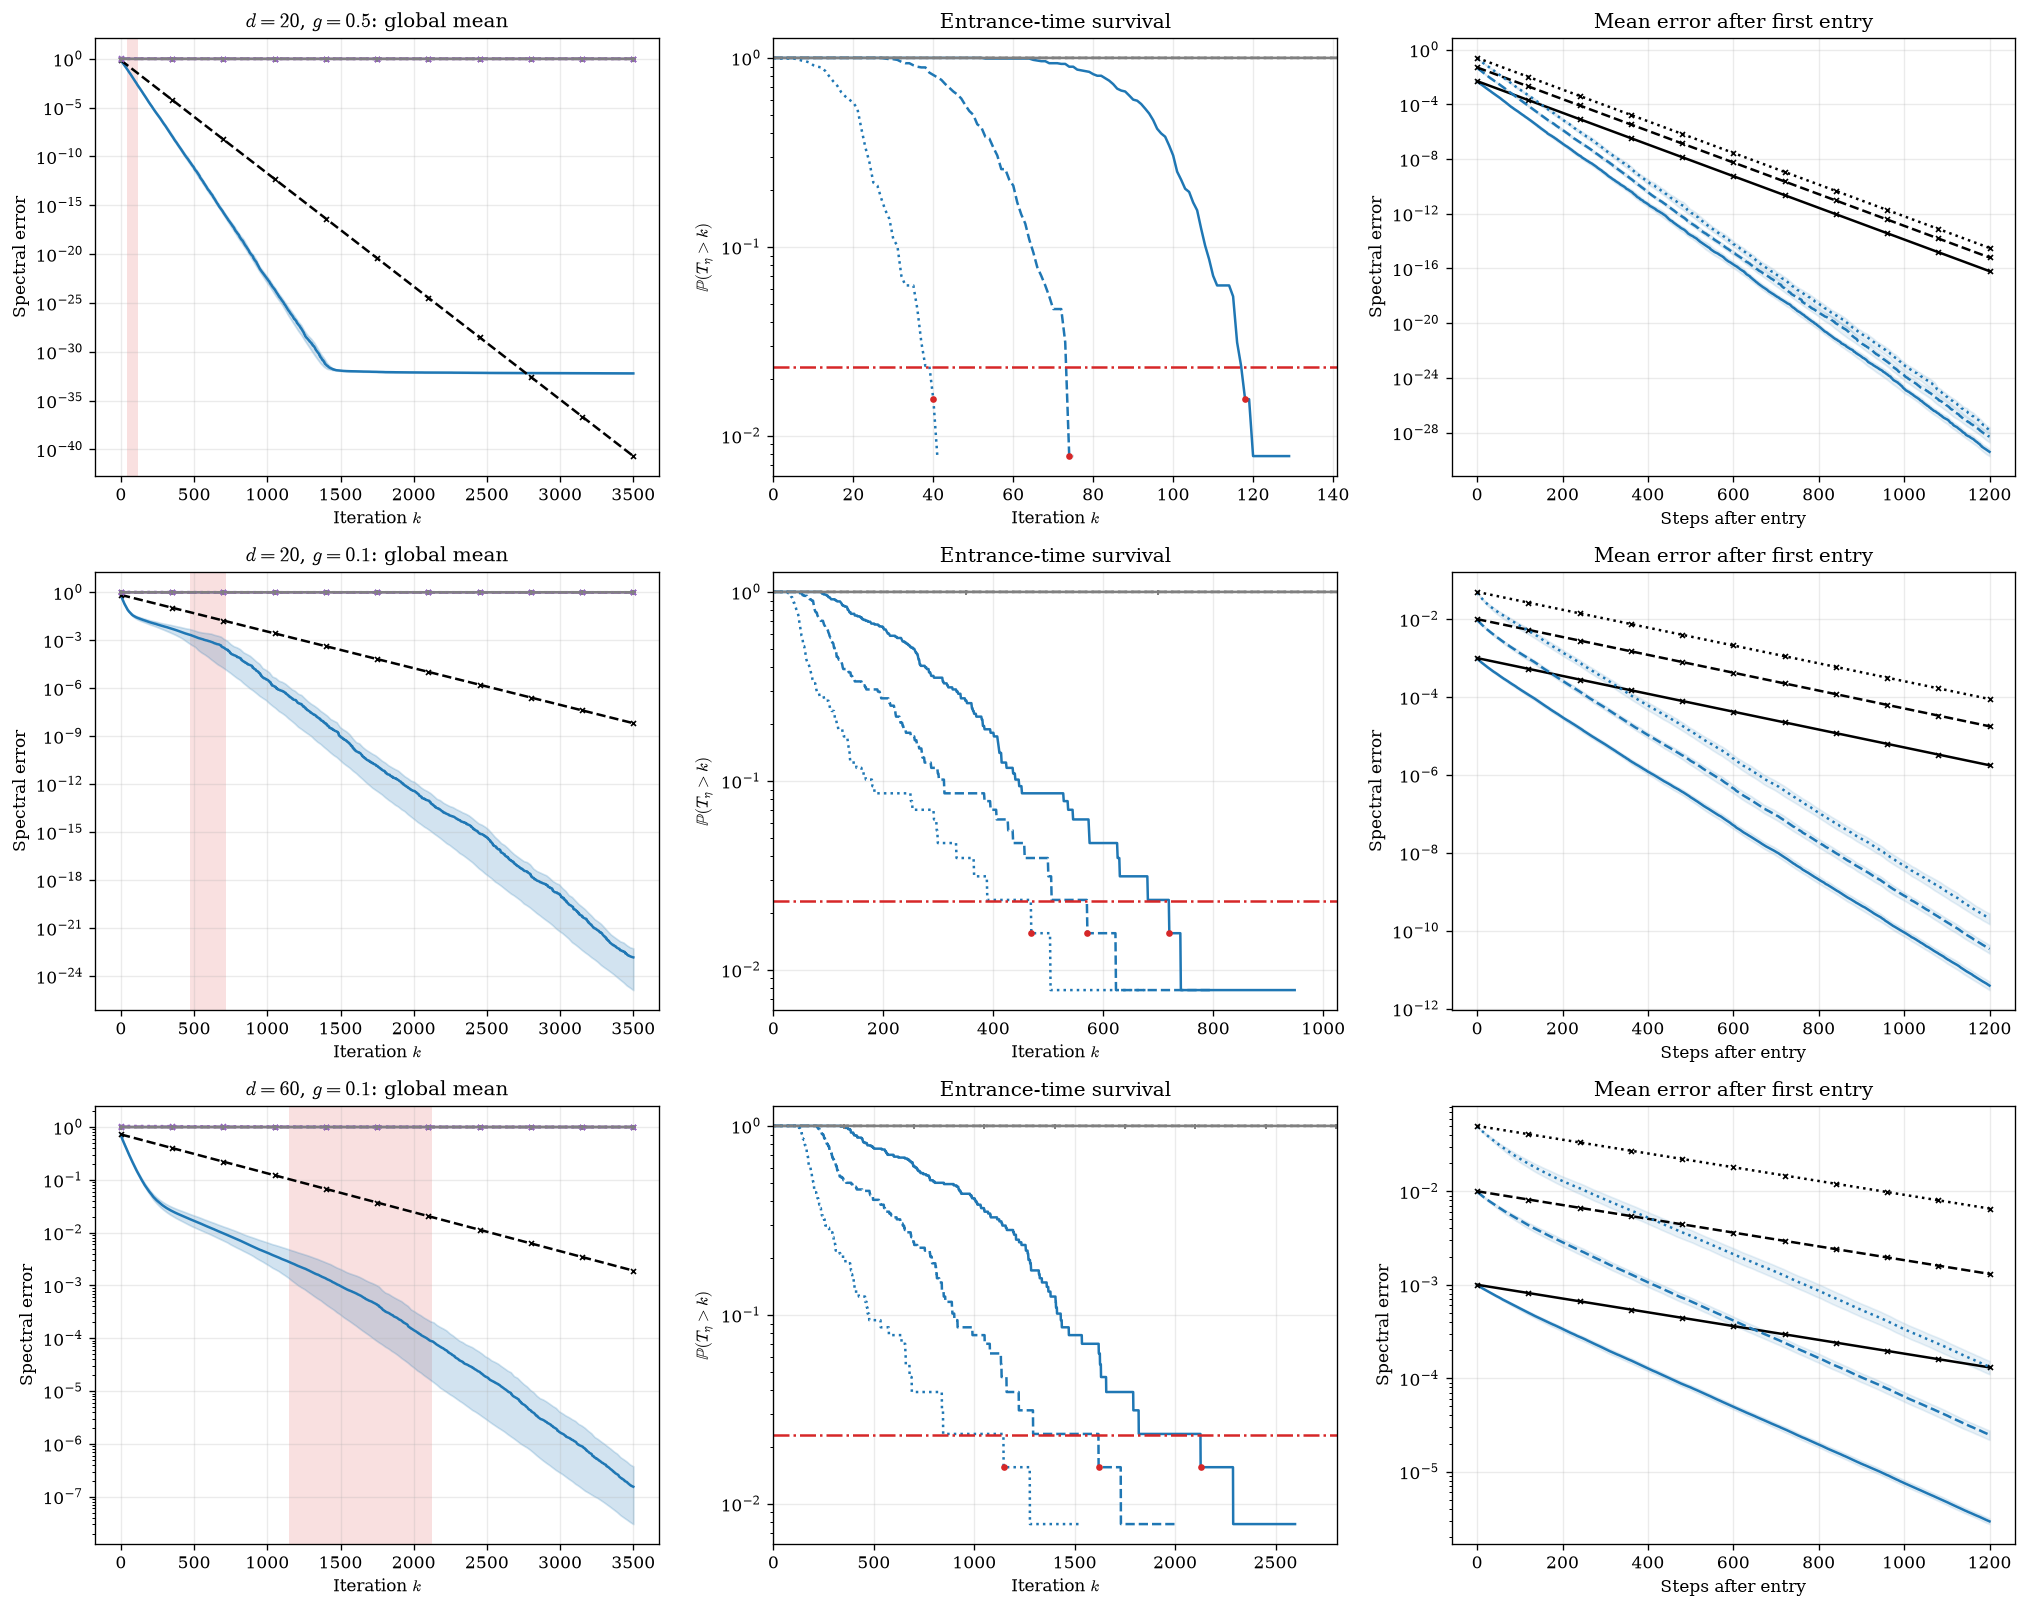

In [5]:
entry_time_summary = []
fig, axes = plt.subplots(len(cfg['cases']), 3, figsize=(17, 4.5*len(cfg['cases'])), squeeze=False)
for row, (d,gap) in enumerate(cfg['cases']):
    items = [x for x in experiments if x['d']==d and x['gap']==gap]
    E = items[0]['data']['errors']; k = np.arange(E.shape[1])
    ax = axes[row,0]
    ax.semilogy(k, E.mean(axis=0), color='C0')
    c0=items[0]['constants']
    logq0=np.log1p(-c0['delta']/((d-1)*c0['width']))
    # Limiting local reference only: not a global error bound.
    ax.semilogy(k,E[:,0].mean()*np.exp(logq0*k),color='black',
                linestyle='--',marker='x',markevery=max(1,len(k)//10),markersize=3)
    idx, low, high = bootstrap_mean_band(E, seed=SEED+row, resamples=cfg['bootstrap'])
    ax.fill_between(idx, low, high, color='C0', alpha=.2)
    entrance_horizons = []
    entry_95_times = []
    entry_95_censored = False
    skipped = []
    for item in items:
        eta, c = item['eta'], item['constants']; style=ETA_STYLES[eta]
        np.testing.assert_array_equal(E, item['data']['errors'])
        axes[row,0].semilogy(k, global_bound(cfg['steps'],c,eta), color='C4',
                            linestyle=style, marker='x', markevery=max(1,len(k)//10), markersize=3)
        # Keep the entrance contribution; the black curve is a q0 reference,
        # not a term of the original global decomposition.
        j = k//2
        axes[row,0].semilogy(k, c['width']*np.exp(np.log1p(-c['p'])*j),
                            color='gray', linestyle=style, marker='+', markevery=max(1,len(k)//10), markersize=3)
        T = item['data']['hit_times']
        # First crossing of the horizontal zero-survivor 95% upper-limit reference.
        # This is a reference-level crossing, not a confidence bound at nonzero counts.
        # Censored trajectories count as not entered, never as early entries.
        upper_limit = 1-.05**(1/len(T))
        rank = int(np.ceil((1-upper_limit)*len(T)))
        observed = np.sort(T[T >= 0])
        entry95 = int(observed[rank-1]) if len(observed) >= rank else None
        entry_time_summary.append(dict(d=d,gap=gap,eta=eta,runs=len(T),
                                      crossing_iteration=entry95,reference_level=upper_limit,censored=entry95 is None))
        if entry95 is None:
            entry_95_censored = True
        else:
            entry_95_times.append(entry95)
            axes[row,1].plot(entry95,np.mean((T<0)|(T>entry95)),
                             marker='o',color='C3',markersize=3,zorder=5)
        survival = np.mean((T[:,None]<0)|(T[:,None]>k[None,:]),axis=0)
        axes[row,1].semilogy(k,np.where(survival>0,survival,np.nan),color='C0',linestyle=style)
        axes[row,1].semilogy(k,np.exp(k*np.log1p(-c['p'])),color='gray',linestyle=style,
                            marker='+',markevery=max(1,len(k)//10),markersize=3)
        entrance_horizons.append(cfg['steps'] if np.any(T<0) else max(1,int(np.ceil(1.08*T.max()))))
        if item['post'] is not None:
            post=item['post']; n=np.arange(post.shape[1])
            axes[row,2].semilogy(n,post.mean(axis=0),color='C0',linestyle=style)
            idx,low,high=bootstrap_mean_band(post,seed=SEED+200+row,resamples=cfg['bootstrap'])
            axes[row,2].fill_between(idx,low,high,color='C0',alpha=.1)
            axes[row,2].semilogy(n,eta*c['delta']*np.exp(logq0*n),color='black',linestyle=style,
                                marker='x',markevery=max(1,len(n)//10),markersize=3)
        else:
            skipped.append(f'{eta:g}')
    # Span the earliest and latest upper-limit reference crossings across eta.
    if entry_95_times:
        earliest = min(entry_95_times)
        latest = cfg['steps'] if entry_95_censored else max(entry_95_times)
        axes[row,0].axvspan(earliest,latest,facecolor='C3',alpha=.14,
                            edgecolor='none',zorder=0)
        if earliest == latest:
            axes[row,0].axvline(earliest,color='C3',alpha=.6,linewidth=1)
    else:
        axes[row,0].text(.98,.03,'Upper-limit crossing not observed within budget',
            transform=axes[row,0].transAxes,ha='right',va='bottom',fontsize=8,color='C3')
    axes[row,0].set(xlabel='Iteration $k$',ylabel='Spectral error',title=f'$d={d}$, $g={gap:g}$: global mean')
    axes[row,1].axhline(1-.05**(1/cfg['runs']),color='C3',linestyle='-.')
    axes[row,1].set(xlabel='Iteration $k$',ylabel=r'$\mathbb{P}(T_\eta>k)$',
                    title='Entrance-time survival',xlim=(0,max(entrance_horizons)))
    axes[row,2].set(xlabel='Steps after entry',ylabel='Spectral error',title='Mean error after first entry')
    # if skipped:
with (OUT / f'survival_upper_limit_crossings_{ETA_TAG}.csv').open('w',newline='') as f:
    import csv
    writer=csv.DictWriter(f,fieldnames=list(entry_time_summary[0]))
    writer.writeheader();writer.writerows(entry_time_summary)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
})
fig.tight_layout()
fig.savefig(OUT / f'global_entrance_contraction_{ETA_TAG}.pdf')
fig.savefig(OUT / '02_global_entrance_and_contraction_cell4.png')
plt.show()
